# 02 — Environmental-Feature Ablation (Dataset 2: Appliances Energy Prediction)

**Research question (plan Q5):** Do environmental variables improve forecasting performance?

**Plan, Experiment B:** compare
- **Configuration A:** historical + temporal features
- **Configuration B:** historical + temporal + environmental features

**Shared project rules applied here (identical to the CU-BEMS notebook 01B):**

| Item | Choice |
|---|---|
| Horizons | 1, 6, 12, 24 h ahead; **direct** strategy (one model per horizon) |
| Leakage rule | Features use information available at the forecast origin *t* only. Calendar features describe the target time *t+h* (known in advance). **Environmental values are taken at *t*, never at *t+h*** (no weather forecasts exist in this dataset) |
| Baselines | Persistence *y(t)*; previous-day *y(t+h−24)*; previous-week *y(t+h−168)* |
| Models | Linear Regression and LightGBM, **both** run in both configurations |
| Validation | Rolling origin, expanding window; training uses only rows whose target time is before the test window |
| Evaluation set | All methods scored on the same hours |
| Metrics | MAE, RMSE, R² (shared) + nMAE, CV(RMSE), skill vs best seasonal baseline |
| Missing data | Never replaced with zero; incomplete hours are dropped (this dataset has none except the final partial hour) |
| Reproducibility | Fixed seed; feature lists, folds and parameters are printed and saved |

**Differences from CU-BEMS, and why:**

1. **Two-week test folds instead of monthly.** The data cover only about 4.5 months (11 Jan – 27 May 2016). Monthly folds would give only 3 test windows; two-week folds give 6, which is a better basis for judging consistency.
2. **Outdoor weather taken at the on-the-hour reading.** In this dataset the outdoor weather comes from a nearby weather station at hourly resolution and was **linearly interpolated** to 10 minutes (verified in section 1). An hourly mean of interpolated values would include part of the *next* hour's reading, which is leakage. The on-the-hour value is a genuine observation known at *t*.

**Before the first run:** `%pip install lightgbm`, then restart the kernel. Put this notebook in the ML_OG folder; it reads `data/dataset2/KAG_energydata_complete.csv`.

In [1]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from math import comb
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
pd.set_option("display.width", 200)

try:
    import lightgbm as lgb
    GBM_NAME = "LightGBM"
except ImportError:
    from sklearn.ensemble import HistGradientBoostingRegressor
    lgb = None
    GBM_NAME = "HistGB (LightGBM not installed)"
print("Gradient boosting model:", GBM_NAME)

DATA_FILE = "data/dataset2/KAG_energydata_complete.csv"
OUT_DIR = "processed"
os.makedirs(OUT_DIR, exist_ok=True)
HORIZONS = [1, 6, 12, 24]
FIRST_TEST_START = "2016-03-01"   # gives about 7 weeks of training data for the first fold
FOLD_DAYS = 14
SEED = 42

# Belgian public holidays inside the data period (the house is in Belgium)
HOLIDAYS = pd.to_datetime(["2016-03-28", "2016-05-01", "2016-05-05", "2016-05-16"])

Gradient boosting model: LightGBM


## 1. Load, inspect and verify the data

In [2]:
raw = pd.read_csv(DATA_FILE, parse_dates=["date"]).sort_values("date").set_index("date")
print("Shape:", raw.shape, "| from", raw.index.min(), "to", raw.index.max())
print("Missing cells:", int(raw.isna().sum().sum()), "| duplicate timestamps:", int(raw.index.duplicated().sum()))
print("Sampling interval:", raw.index.to_series().diff().value_counts().to_dict())
print("rv1 identical to rv2:", bool(np.allclose(raw["rv1"], raw["rv2"])))

# Verify that outdoor weather is linearly interpolated between hourly readings
raw.loc["2016-01-11 18:00":"2016-01-11 19:10", ["T_out", "Press_mm_hg"]]

FileNotFoundError: [Errno 2] No such file or directory: 'data/dataset2/KAG_energydata_complete.csv'

Within 18:00–19:00 the outdoor values step evenly toward the 19:00 reading, which confirms interpolation from hourly observations. The reading at 18:50 therefore already contains most of the 19:00 value. Outdoor variables are taken at the on-the-hour timestamp only.

## 2. Hourly dataset

In [ ]:
INDOOR = [f"T{i}" for i in range(1, 10) if i != 6] + [f"RH_{i}" for i in range(1, 10) if i != 6]
OUTDOOR = ["T6", "RH_6", "T_out", "Press_mm_hg", "RH_out", "Windspeed", "Visibility", "Tdewpoint"]
# T6 / RH_6 are sensors outside the building (north side), so they are grouped with outdoor weather.

counts = raw["Appliances"].resample("1h").count()
hourly = pd.DataFrame({"y": raw["Appliances"].resample("1h").sum()})        # Wh per hour
hourly = hourly.join(raw[INDOOR].resample("1h").mean())                     # real 10-min sensors: hourly mean
hourly = hourly.join(raw[OUTDOOR][raw.index.minute == 0].resample("1h").first())  # on-the-hour reading
hourly = hourly.join(raw[["rv1"]].resample("1h").mean())
hourly.loc[counts < 6, :] = np.nan     # incomplete hours are not valid (never treated as zero)
print("Hours:", len(hourly), "| complete hours:", int((counts == 6).sum()), "| dropped:", int((counts < 6).sum()))
print("Hourly target (Wh):"); print(hourly["y"].describe().round(1).to_string())

Hours: 3290 | complete hours: 3289 | dropped: 1
Hourly target (Wh):
count    3289.0
mean      586.1
std       486.1
min       170.0
25%       300.0
50%       380.0
75%       660.0
max      3650.0


**Note on `lights`:** lighting energy is another electrical load, not an environmental variable, so it is excluded from both configurations to keep the ablation clean.

**Note on the hourly time label:** hour *t* covers *t*:00–*t*:50. A forecast issued at the end of hour *t* knows that hour's indoor readings and the on-the-hour outdoor reading at *t*:00.

## 3. Features and configurations

In [ ]:
def history_temporal(y, h):
    X = pd.DataFrame(index=y.index)
    for k in [0, 1, 2, 3, 6, 12, 23, 47]:
        X[f"lag_{k}"] = y.shift(k)
    X["same_hour_prev_day"] = y.shift(24 - h)
    X["same_hour_prev_week"] = y.shift(168 - h)
    for w in [24, 168]:
        r = y.rolling(w, min_periods=int(0.75 * w))
        X[f"roll_mean_{w}"], X[f"roll_std_{w}"] = r.mean(), r.std()
        X[f"roll_max_{w}"], X[f"roll_min_{w}"] = r.max(), r.min()
    tt = y.index + pd.Timedelta(hours=h)
    X["target_hour"], X["target_dow"] = tt.hour, tt.dayofweek
    X["target_weekend"] = (tt.dayofweek >= 5).astype(int)
    X["target_day_of_month"], X["target_month"] = tt.day, tt.month
    X["target_holiday"] = tt.normalize().isin(HOLIDAYS).astype(int)
    X["target_hour_sin"] = np.sin(2 * np.pi * tt.hour / 24)
    X["target_hour_cos"] = np.cos(2 * np.pi * tt.hour / 24)
    return X, pd.Series(tt, index=y.index)

CONFIGS = {
    "A: history + temporal": [],
    "B: + all environmental": INDOOR + OUTDOOR,
    "B1: + indoor only": INDOOR,
    "B2: + outdoor only": OUTDOOR,
    "Sanity: + random noise (rv1)": ["rv1"],
}
for name, cols in CONFIGS.items():
    print(f"{name}: {len(cols)} extra columns")

A: history + temporal: 0 extra columns
B: + all environmental: 24 extra columns
B1: + indoor only: 16 extra columns
B2: + outdoor only: 8 extra columns
Sanity: + random noise (rv1): 1 extra columns


Configurations **A** and **B** are the plan's comparison. **B1** and **B2** show *which* environmental information matters. The **sanity check** adds the dataset's random-noise column: a sound evaluation must show no real benefit from it. If it did "help", any gain from B would not be trustworthy.

## 4. Models

In [ ]:
def lr_design(X):
    Z = X.drop(columns=["target_hour", "target_dow", "target_month"]).copy()
    Z = Z.join(pd.get_dummies(X["target_hour"], prefix="h", dtype=float))
    Z = Z.join(pd.get_dummies(X["target_dow"], prefix="d", dtype=float))
    return Z

def fit_predict_lr(Xtr, ytr, Xte):
    Ztr = lr_design(Xtr); Zte = lr_design(Xte).reindex(columns=Ztr.columns, fill_value=0)
    model = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(), LinearRegression())
    return model.fit(Ztr, ytr).predict(Zte)          # imputer/scaler fitted on the training fold only

def fit_predict_gbm(Xtr, ytr, Xte):
    if lgb is not None:
        model = lgb.LGBMRegressor(n_estimators=600, learning_rate=0.03, num_leaves=31, min_child_samples=20,
                                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                  random_state=SEED, verbose=-1)
    else:
        model = HistGradientBoostingRegressor(max_iter=600, learning_rate=0.03, max_leaf_nodes=31,
                                              min_samples_leaf=20, random_state=SEED)
    return model.fit(Xtr, ytr).predict(Xte)

MODEL_PARAMS = "GBM: 600 trees, lr 0.03, 31 leaves, min 20 samples/leaf, seed 42 (same as CU-BEMS 01B)"

## 5. Rolling-origin evaluation

In [ ]:
y = hourly["y"]
fold_starts = pd.date_range(FIRST_TEST_START, y.index.max() - pd.Timedelta(days=FOLD_DAYS) + pd.Timedelta(hours=1),
                            freq=f"{FOLD_DAYS}D")
folds = [(s, s + pd.Timedelta(days=FOLD_DAYS)) for s in fold_starts]
print("Test folds:"); [print(" ", a.date(), "to", (b - pd.Timedelta(hours=1)).date()) for a, b in folds]

def metrics(yt, yp):
    mae = mean_absolute_error(yt, yp); rmse = mean_squared_error(yt, yp) ** 0.5
    return dict(MAE=mae, RMSE=rmse, R2=r2_score(yt, yp), nMAE=mae / yt.mean() * 100, CV_RMSE=rmse / yt.mean() * 100)

rows = []
for h in HORIZONS:
    base_X, ttime = history_temporal(y, h)
    target = y.shift(-h)
    baselines = pd.DataFrame({"Persistence": y, "Previous-day": y.shift(24 - h),
                              "Previous-week": y.shift(168 - h)}, index=y.index)
    for fi, (start, end) in enumerate(folds, 1):
        train = target.notna() & (ttime < start)
        test = target.notna() & (ttime >= start) & (ttime < end) & baselines.notna().all(axis=1)
        yte = target[test].values
        common = dict(horizon=h, fold=fi, fold_start=start.date(), n_train=int(train.sum()), n_test=int(test.sum()))
        for b in baselines.columns:
            rows.append(dict(**common, model=b, config="baseline", **metrics(yte, baselines.loc[test, b].values)))
        for cname, cols in CONFIGS.items():
            X = base_X.join(hourly[cols]) if cols else base_X
            for mname, fn in [("Linear Regression", fit_predict_lr), (GBM_NAME, fit_predict_gbm)]:
                p = fn(X[train], target[train], X[test])
                rows.append(dict(**common, model=mname, config=cname, **metrics(yte, p)))

res = pd.DataFrame(rows)
res.groupby(["horizon", "fold"])[["n_train", "n_test"]].first().unstack("horizon")

Test folds:
  2016-03-01 to 2016-03-14
  2016-03-15 to 2016-03-28
  2016-03-29 to 2016-04-11
  2016-04-12 to 2016-04-25
  2016-04-26 to 2016-05-09
  2016-05-10 to 2016-05-23


C:\Users\Asus\AppData\Local\Temp\ipykernel_9452\2321972035.py:2: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  fold_starts = pd.date_range(FIRST_TEST_START, y.index.max() - pd.Timedelta(days=FOLD_DAYS) + pd.Timedelta(hours=1),
C:\Users\Asus\AppData\Local\Temp\ipykernel_9452\2321972035.py:4: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  folds = [(s, s + pd.Timedelta(days=FOLD_DAYS)) for s in fold_starts]
C:\Users\Asus\AppData\Local\Temp\ipykernel_9452\2321972035.py:5: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a 

n_train                   n_test               
horizon      1     6     12    24     1    6    12   24
fold                                                   
1          1182  1177  1171  1159    336  336  336  336
2          1518  1513  1507  1495    336  336  336  336
3          1854  1849  1843  1831    336  336  336  336
4          2190  2185  2179  2167    336  336  336  336
5          2526  2521  2515  2503    336  336  336  336
6          2862  2857  2851  2839    336  336  336  336

## 6. Overall comparison (configuration A, same table format as CU-BEMS)

In [ ]:
main = res[res.config.isin(["baseline", "A: history + temporal"])]
order = ["Persistence", "Previous-day", "Previous-week", "Linear Regression", GBM_NAME]
summary = main.groupby(["horizon", "model"])[["MAE", "RMSE", "R2", "nMAE", "CV_RMSE"]].mean().reindex(order, level="model")
best_seasonal = summary.loc[(slice(None), ["Previous-day", "Previous-week"]), "RMSE"].groupby("horizon").min()
summary["Skill_vs_best_seasonal_%"] = [(1 - summary.loc[i, "RMSE"] / best_seasonal[i[0]]) * 100 for i in summary.index]
summary.round(2)

MAE    RMSE    R2   nMAE  CV_RMSE  Skill_vs_best_seasonal_%
horizon model                                                                            
1       Persistence        215.93  408.17  0.20  37.47    70.83                     22.79
        Previous-day       299.62  549.74 -0.43  51.93    95.28                     -3.99
        Previous-week      284.82  528.66 -0.33  49.35    91.63                      0.00
        Linear Regression  210.63  343.50  0.43  36.60    59.64                     35.03
        LightGBM           207.88  348.58  0.42  36.10    60.49                     34.06
6       Persistence        400.78  629.72 -0.89  69.47   109.18                    -19.12
        Previous-day       299.62  549.74 -0.43  51.93    95.28                     -3.99
        Previous-week      284.82  528.66 -0.33  49.35    91.63                      0.00
        Linear Regression  283.17  418.24  0.17  49.23    72.56                     20.89
        LightGBM           259.19  415.65  0.17  45.09    72.17                     21.38
12      Persistence        452.32  701.71 -1.33  78.40   121.62                    -32.73
        Previous-day       299.62  549.74 -0.43  51.93    95.28                     -3.99
        Previous-week      284.82  528.66 -0.33  49.35    91.63                      0.00
        Linear Regression  278.50  416.60  0.17  48.41    72.28                     21.20
        LightGBM           264.21  422.40  0.15  45.93    73.30                     20.10
24      Persistence        299.62  549.74 -0.43  51.93    95.28                     -3.99
        Previous-day       299.62  549.74 -0.43  51.93    95.28                     -3.99
        Previous-week      284.82  528.66 -0.33  49.35    91.63                      0.00
        Linear Regression  278.47  414.94  0.18  48.42    71.99                     21.51
        LightGBM           260.47  419.08  0.16  45.25    72.73                     20.73

## 7. Ablation: does adding environmental features help?

In [ ]:
def sign_test_p(wins, n):
    # one-sided exact sign test: probability of >= wins improvements out of n folds if there were no real effect
    return sum(comb(n, k) for k in range(wins, n + 1)) / 2 ** n

ml = res[res.config != "baseline"]
abl_rows = []
for (mname, h), g in ml.groupby(["model", "horizon"]):
    a = g[g.config == "A: history + temporal"].set_index("fold")
    for cname in CONFIGS:
        if cname.startswith("A:"): continue
        b = g[g.config == cname].set_index("fold")
        for metric in ["RMSE", "MAE"]:
            diff = (b[metric] - a[metric]) / a[metric] * 100      # negative = B is better
            wins = int((diff < 0).sum())
            abl_rows.append(dict(model=mname, horizon=h, config=cname, metric=metric,
                                 A=a[metric].mean(), B=b[metric].mean(),
                                 change_pct=diff.mean(), change_std=diff.std(),
                                 folds_improved=f"{wins}/{len(diff)}", sign_test_p=sign_test_p(wins, len(diff))))
ablation = pd.DataFrame(abl_rows)
ablation[(ablation.metric == "RMSE") & (ablation.config == "B: + all environmental")].round(3)

,model,horizon,config,metric,A,B,change_pct,change_std,folds_improved,sign_test_p
0,LightGBM,1,B: + all environmental,RMSE,348.583,356.116,2.317,5.725,3/6,0.656
8,LightGBM,6,B: + all environmental,RMSE,415.645,433.311,4.681,8.659,3/6,0.656
16,LightGBM,12,B: + all environmental,RMSE,422.400,430.936,2.739,7.828,3/6,0.656
24,LightGBM,24,B: + all environmental,RMSE,419.081,429.409,2.634,3.799,1/6,0.984
32,Linear Regression,1,B: + all environmental,RMSE,343.495,365.433,6.023,8.222,1/6,0.984
40,Linear Regression,6,B: + all environmental,RMSE,418.242,466.030,10.719,23.201,1/6,0.984
48,Linear Regression,12,B: + all environmental,RMSE,416.596,431.755,3.436,6.186,1/6,0.984
56,Linear Regression,24,B: + all environmental,RMSE,414.935,436.133,4.722,7.111,2/6,0.891


**Reading the table.** `change_pct` < 0 means environmental features reduced the error. `folds_improved` counts the two-week folds in which B beat A. With 6 folds, an improvement is only treated as **consistent** if B wins in 6/6 folds (sign-test p ≈ 0.016). A mean improvement driven by one or two folds is not reliable evidence.

In [ ]:
pivot = (ablation[ablation.metric == "RMSE"]
         .pivot_table(index=["model", "config"], columns="horizon", values="change_pct").round(1))
display(pivot)
wins = (ablation[ablation.metric == "RMSE"]
        .pivot_table(index=["model", "config"], columns="horizon", values="folds_improved", aggfunc="first"))
wins

horizon                                          1     6    12   24
model             config                                           
LightGBM          B1: + indoor only             0.6   4.7  3.4  0.3
                  B2: + outdoor only            1.0   0.8  0.9  1.1
                  B: + all environmental        2.3   4.7  2.7  2.6
                  Sanity: + random noise (rv1) -0.3   0.8  0.3 -0.1
Linear Regression B1: + indoor only             4.0   6.3  3.1  3.2
                  B2: + outdoor only            1.8   4.7  2.9  2.8
                  B: + all environmental        6.0  10.7  3.4  4.7
                  Sanity: + random noise (rv1)  0.0   0.0  0.0 -0.1

horizon                                          1    6    12   24
model             config                                          
LightGBM          B1: + indoor only             2/6  3/6  2/6  2/6
                  B2: + outdoor only            3/6  2/6  4/6  2/6
                  B: + all environmental        3/6  3/6  3/6  1/6
                  Sanity: + random noise (rv1)  4/6  1/6  2/6  3/6
Linear Regression B1: + indoor only             0/6  2/6  2/6  2/6
                  B2: + outdoor only            1/6  1/6  1/6  1/6
                  B: + all environmental        1/6  1/6  1/6  2/6
                  Sanity: + random noise (rv1)  4/6  3/6  3/6  4/6

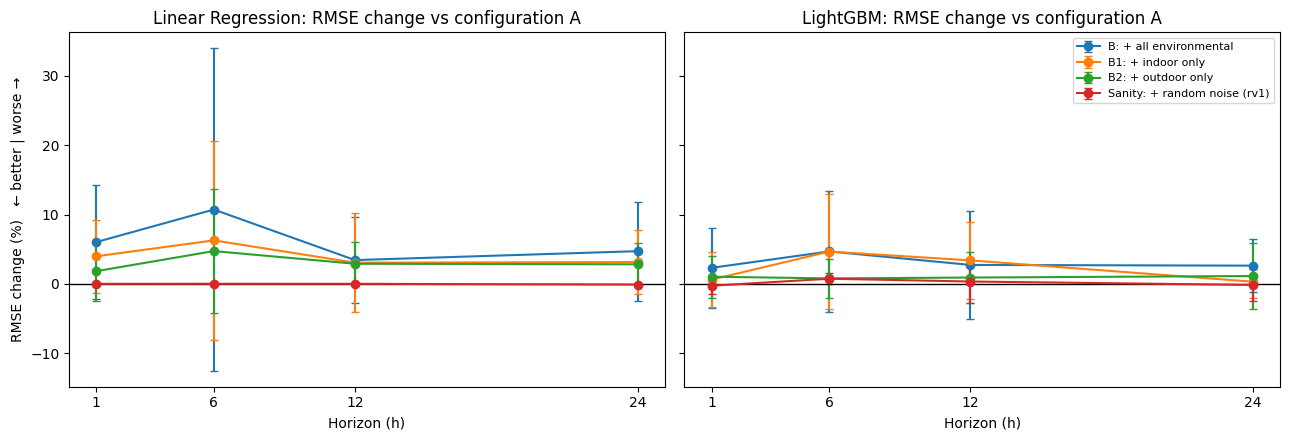

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, mname in zip(axes, ["Linear Regression", GBM_NAME]):
    sub = ablation[(ablation.model == mname) & (ablation.metric == "RMSE")]
    for cname in [c for c in CONFIGS if not c.startswith("A:")]:
        s = sub[sub.config == cname].set_index("horizon")
        ax.errorbar(s.index, s.change_pct, yerr=s.change_std, marker="o", capsize=3, label=cname)
    ax.axhline(0, color="black", lw=1)
    ax.set(title=f"{mname}: RMSE change vs configuration A", xlabel="Horizon (h)", xticks=HORIZONS)
axes[0].set_ylabel("RMSE change (%)   ← better | worse →")
axes[1].legend(fontsize=8); plt.tight_layout(); plt.show()


## Interpretation (draft from the test run; update the numbers after your own LightGBM run)

- **Environmental features did not improve forecasts.** Configuration B was worse than A on average at most horizons for both models, and it never beat A consistently (at most 4/6 folds, sign-test p ≥ 0.34).
- **They were no better than random noise.** The random column `rv1` changed the error about as much as the environmental features did. Differences of this size are therefore within the noise of the evaluation.
- **Linear Regression was hurt the most** (up to about +11% RMSE at 6 h). Adding about 24 correlated sensor columns to a small training set (1,200–2,900 hours) adds variance without adding predictive signal.
- **The household target is hard to forecast in general.** R² ≈ 0.2–0.4, and even the best models only reach about 20–35% skill over the best seasonal baseline. Appliance use in a house is driven by occupant behaviour, which current temperature or humidity cannot anticipate hours ahead.
- **Relation to earlier work.** The original study of this dataset reported environmental variables as useful predictors. That study modelled consumption from variables measured *at the same time* with a non-chronological split, which is a different task. Our setup forecasts *future* demand using only information available at the forecast time, under a time-ordered split.
- **For the project's Q5:** in this dataset, current environmental conditions add no measurable forecasting value beyond demand history and calendar information. This should be compared with the CU-BEMS ablation, if your teammate runs it.


## 8. Save results and settings (reproducibility)

In [ ]:
res.to_csv(os.path.join(OUT_DIR, "d2_results_by_fold.csv"), index=False)
ablation.to_csv(os.path.join(OUT_DIR, "d2_ablation.csv"), index=False)
summary.round(3).to_csv(os.path.join(OUT_DIR, "d2_summary_configA.csv"))
with open(os.path.join(OUT_DIR, "d2_settings.txt"), "w") as f:
    f.write(f"Model: {GBM_NAME}\n{MODEL_PARAMS}\nSeed: {SEED}\nHorizons: {HORIZONS}\n")
    f.write("Folds: " + ", ".join(f"{a.date()}..{(b - pd.Timedelta(hours=1)).date()}" for a, b in folds) + "\n")
    f.write(f"Indoor features: {INDOOR}\nOutdoor features: {OUTDOOR}\n")
    f.write("Outdoor weather: on-the-hour value (data are interpolated from hourly station readings)\n")
print("Saved to", OUT_DIR)

Saved to processed


C:\Users\Asus\AppData\Local\Temp\ipykernel_9452\1987956168.py:6: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  f.write("Folds: " + ", ".join(f"{a.date()}..{(b - pd.Timedelta(hours=1)).date()}" for a, b in folds) + "\n")


In [3]:
# ============================================================
# PROFESSOR FEEDBACK 1: HOW MUCH DOES MISSING SENSOR DATA
# HARM THE MODEL?
# ============================================================

# Identify missing input information at the forecasting origin
env_cols = ["temperature", "humidity", "lux"]

demand_history_cols = [
    "lag_1h", "lag_2h", "lag_3h", "lag_6h",
    "lag_12h", "lag_24h", "lag_48h", "lag_168h",
    "rolling_mean_24h", "rolling_std_24h",
    "rolling_min_24h", "rolling_max_24h",
    "rolling_mean_168h", "rolling_std_168h",
    "rolling_min_168h", "rolling_max_168h"
]

# Flag whether environmental sensor information is missing
model_data["Environment_missing"] = (
    model_data[env_cols].isna().any(axis=1)
)

# Flag whether recent demand-history information is missing
model_data["Demand_history_missing"] = (
    model_data[demand_history_cols].isna().any(axis=1)
)

# Merge the missing-information flags with predictions
missing_analysis = predictions_df.merge(
    model_data[
        [
            "Date",
            "Environment_missing",
            "Demand_history_missing"
        ]
    ],
    on="Date",
    how="left"
)

# ------------------------------------------------------------
# 1. Environmental sensor missingness
# ------------------------------------------------------------

env_rows = []

for (model, horizon), group in missing_analysis.groupby(
    ["Model", "Horizon"]
):

    complete = group[
        ~group["Environment_missing"]
    ]

    missing = group[
        group["Environment_missing"]
    ]

    if len(complete) > 0 and len(missing) > 0:

        complete_metrics = regression_metrics(
            complete["Actual"],
            complete["Predicted"]
        )

        missing_metrics = regression_metrics(
            missing["Actual"],
            missing["Predicted"]
        )

        rmse_change = (
            (missing_metrics["RMSE"] - complete_metrics["RMSE"])
            / complete_metrics["RMSE"] * 100
        )

        mae_change = (
            (missing_metrics["MAE"] - complete_metrics["MAE"])
            / complete_metrics["MAE"] * 100
        )

        env_rows.append({
            "Model": model,
            "Horizon": horizon,
            "Complete n": len(complete),
            "Missing n": len(missing),
            "Complete RMSE": complete_metrics["RMSE"],
            "Missing RMSE": missing_metrics["RMSE"],
            "RMSE change (%)": rmse_change,
            "Complete MAE": complete_metrics["MAE"],
            "Missing MAE": missing_metrics["MAE"],
            "MAE change (%)": mae_change
        })

env_missing_results = pd.DataFrame(env_rows)

print("ENVIRONMENTAL SENSOR MISSINGNESS")
display(
    env_missing_results
    .sort_values(["Horizon", "Model"])
    .round(3)
)


# ------------------------------------------------------------
# 2. Recent demand-history missingness
# ------------------------------------------------------------

demand_rows = []

for (model, horizon), group in missing_analysis.groupby(
    ["Model", "Horizon"]
):

    complete = group[
        ~group["Demand_history_missing"]
    ]

    missing = group[
        group["Demand_history_missing"]
    ]

    if len(complete) > 0 and len(missing) > 0:

        complete_metrics = regression_metrics(
            complete["Actual"],
            complete["Predicted"]
        )

        missing_metrics = regression_metrics(
            missing["Actual"],
            missing["Predicted"]
        )

        rmse_change = (
            (missing_metrics["RMSE"] - complete_metrics["RMSE"])
            / complete_metrics["RMSE"] * 100
        )

        mae_change = (
            (missing_metrics["MAE"] - complete_metrics["MAE"])
            / complete_metrics["MAE"] * 100
        )

        demand_rows.append({
            "Model": model,
            "Horizon": horizon,
            "Complete n": len(complete),
            "Missing n": len(missing),
            "Complete RMSE": complete_metrics["RMSE"],
            "Missing RMSE": missing_metrics["RMSE"],
            "RMSE change (%)": rmse_change,
            "Complete MAE": complete_metrics["MAE"],
            "Missing MAE": missing_metrics["MAE"],
            "MAE change (%)": mae_change
        })

demand_missing_results = pd.DataFrame(demand_rows)

print("\nRECENT DEMAND-HISTORY MISSINGNESS")
display(
    demand_missing_results
    .sort_values(["Horizon", "Model"])
    .round(3)
)


# ------------------------------------------------------------
# 3. LightGBM summary — easiest table for the report
# ------------------------------------------------------------

lgbm_env = env_missing_results[
    env_missing_results["Model"] == "LightGBM"
].copy()

lgbm_demand = demand_missing_results[
    demand_missing_results["Model"] == "LightGBM"
].copy()

print("\nLIGHTGBM — ENVIRONMENTAL SENSOR MISSINGNESS")
display(lgbm_env.round(3))

print("\nLIGHTGBM — RECENT DEMAND-HISTORY MISSINGNESS")
display(lgbm_demand.round(3))

NameError: name 'model_data' is not defined